# 04 — Spectral Analysis

## Objective

The aim of this notebook is to characterise the frequency content of the selected SEEG recording using power spectral density (PSD) estimation.

We will:

- Estimate the power spectral density (PSD) of the recorded signals using Welch's method.
- Examine the distribution of signal power across frequencies.
- Compare the spectral characteristics of the annotated pre- and post-stimulation epochs.
- Examine spectral differences across channels.
- Visualise and document the results, including relevant signal-quality limitations.

This is a descriptive analysis. The objective is to characterise the recorded signals, not to establish physiological or clinical interpretations.

## Recording

This notebook uses the same recording explored in the previous notebooks:

- Participant: `sub-01`
- Session: `ses-01`
- Recording duration: 32 seconds
- Number of channels: 31
- Sampling frequency: 4096 Hz
- Pre-stimulation epoch: 5 seconds
- Post-stimulation epoch: 5 seconds

In [2]:
import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import welch
from pathlib import Path

# Define the path to the raw dataset
RAW_DATA_DIR = Path("../data/raw")

recording_path = (
    RAW_DATA_DIR / "sub-01" / "ses-01" / "ieeg"
    / "sub-01_ses-01_task-dcs_ieeg.vhdr"
)

# Load the recording
raw = mne.io.read_raw_brainvision(
    recording_path,
    preload=True,
    verbose=False
)

print(raw)

<RawBrainVision | sub-01_ses-01_task-dcs_ieeg.eeg, 31 x 131072 (32.0 s), ~31.0 MiB, data loaded>


In [3]:
# Define the annotated epoch timings
sfreq = raw.info["sfreq"]

pre_start = 6.99823
post_start = 19.05
epoch_duration = 5.0

# Extract the pre- and post-stimulation data
pre_data = raw.get_data(
    start=int(pre_start * sfreq),
    stop=int((pre_start + epoch_duration) * sfreq)
)

post_data = raw.get_data(
    start=int(post_start * sfreq),
    stop=int((post_start + epoch_duration) * sfreq)
)

print("Pre-stimulation shape:", pre_data.shape)
print("Post-stimulation shape:", post_data.shape)

Pre-stimulation shape: (31, 20480)
Post-stimulation shape: (31, 20480)


In [4]:
# Inspect the sampling frequency and Nyquist frequency

nyquist_freq = sfreq / 2

print(f"Sampling frequency: {sfreq} Hz")
print(f"Nyquist frequency: {nyquist_freq} Hz")

Sampling frequency: 4096.0 Hz
Nyquist frequency: 2048.0 Hz


In [5]:
# Select one channel for an initial PSD calculation

channel = "B'02-B'03"
channel_idx = raw.ch_names.index(channel)

signal = pre_data[channel_idx]

print("Signal shape:", signal.shape)
print("Sampling frequency:", sfreq)

Signal shape: (20480,)
Sampling frequency: 4096.0


In [6]:
# Estimate the power spectral density using Welch's method

frequencies, psd = welch(
    signal,
    fs=sfreq,
    nperseg=1024
)

print("Frequencies shape:", frequencies.shape)
print("PSD shape:", psd.shape)

Frequencies shape: (513,)
PSD shape: (513,)


## Initial Power Spectral Density (PSD) Estimation

### Method

We began by selecting one channel (`B'02-B'03`) from the pre-stimulation epoch to perform an initial spectral analysis.

Power spectral density (PSD) describes how the power of a signal is distributed across different frequencies. It allows us to examine the frequency components present in the recorded signal and the relative power associated with them.

We used Welch's method, implemented through `scipy.signal.welch`, to estimate the PSD.

### Parameter selection

The following parameters were used:

- **Sampling frequency (`fs`):** 4096 Hz, corresponding to the sampling frequency of the recording.
- **Segment length (`nperseg`):** 1024 samples.

The segment length determines how the signal is divided for spectral estimation. It influences the frequency resolution and the number of segments available for averaging.

With a sampling frequency of 4096 Hz and a segment length of 1024 samples:

- Each segment represents 0.25 seconds of signal.
- The frequency resolution is 4 Hz.
- Welch estimates the PSD from overlapping segments and averages their spectra.

The segment length of 1024 samples was selected as an initial exploratory parameter. Its suitability will be considered when examining the resulting frequency resolution and spectral distributions.

### Initial output

The calculation returned two arrays:

- `frequencies`: 513 frequency values at which the PSD was estimated.
- `psd`: 513 corresponding power spectral density estimates.

Each frequency value is associated with one PSD estimate.

This initial calculation establishes the procedure that will subsequently be applied to the other channels and to the post-stimulation epoch.

### Important considerations

The PSD describes the frequency content of the recorded signal. It does not independently distinguish neural activity from electrical stimulation artefacts or other sources of signal contamination.

The results will therefore be interpreted descriptively, taking into account the signal-quality observations from Notebook 03.

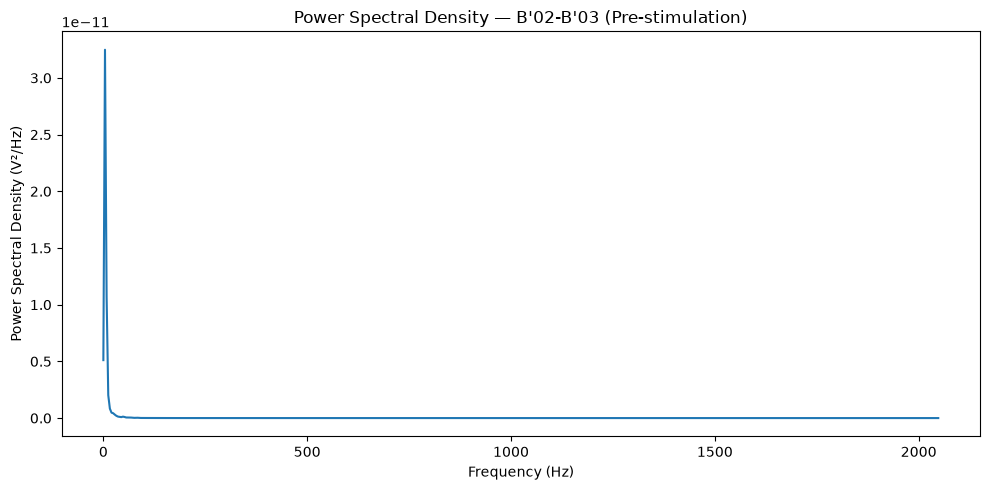

In [7]:
# Plot the estimated power spectral density

plt.figure(figsize=(10, 5))

plt.plot(frequencies, psd)

plt.xlabel("Frequency (Hz)")
plt.ylabel("Power Spectral Density (V²/Hz)")
plt.title(f"Power Spectral Density — {channel} (Pre-stimulation)")

plt.tight_layout()
plt.show()

In [8]:
# Inspect the PSD at 0 Hz and the signal mean

print("First frequency:", frequencies[0], "Hz")
print("PSD at 0 Hz:", psd[0])
print("Signal mean:", np.mean(signal) * 1e6, "µV")

First frequency: 0.0 Hz
PSD at 0 Hz: 5.110467519741279e-12
Signal mean: -7.81289054617673 µV


In [9]:
# Inspect the first 10 frequency and PSD values

pd.DataFrame({
    "Frequency (Hz)": frequencies[:10],
    "PSD (V²/Hz)": psd[:10]
})

,Frequency (Hz),PSD (V²/Hz)
0,0.0,5.110468e-12
1,4.0,3.248315e-11
2,8.0,1.069220e-11
3,12.0,2.021701e-12
4,16.0,8.306744e-13
5,20.0,4.781254e-13
6,24.0,4.281693e-13
7,28.0,3.058778e-13
8,32.0,1.981480e-13
9,36.0,1.293579e-13


In [10]:
# Compare PSD estimates using different segment lengths

segment_lengths = [512, 1024, 2048]

psd_estimates = {}

for n in segment_lengths:
    freqs, power = welch(
        signal,
        fs=sfreq,
        nperseg=n
    )

    psd_estimates[n] = (freqs, power)

    print(
        f"Segment length: {n} | "
        f"Frequency resolution: {sfreq / n:.1f} Hz | "
        f"Frequency points: {len(freqs)}"
    )

Segment length: 512 | Frequency resolution: 8.0 Hz | Frequency points: 257
Segment length: 1024 | Frequency resolution: 4.0 Hz | Frequency points: 513
Segment length: 2048 | Frequency resolution: 2.0 Hz | Frequency points: 1025


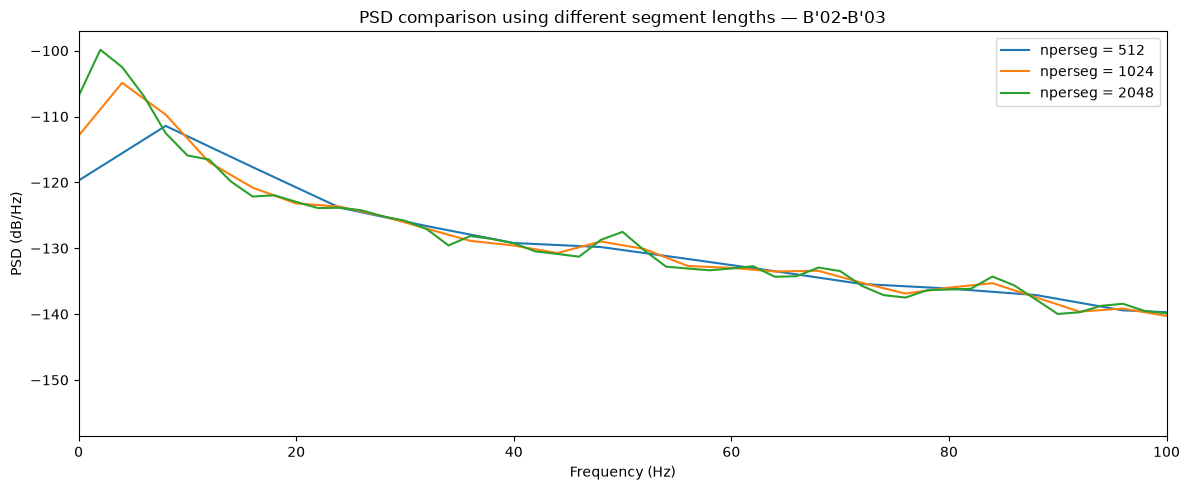

In [11]:
# Compare PSD estimates for different segment lengths

plt.figure(figsize=(12, 5))

for n in segment_lengths:
    freqs, power = psd_estimates[n]

    plt.plot(
        freqs,
        10 * np.log10(power),
        label=f"nperseg = {n}"
    )

plt.xlim(0, 100)
plt.xlabel("Frequency (Hz)")
plt.ylabel("PSD (dB/Hz)")
plt.title(f"PSD comparison using different segment lengths — {channel}")
plt.legend()
plt.tight_layout()
plt.show()

## Selection of Welch's Method Parameters

### Comparison of segment lengths

To evaluate the effect of segment length on PSD estimation, three values were compared using the same channel (`B'02-B'03`) and the same pre-stimulation epoch:

- 512 samples (8 Hz frequency resolution).
- 1024 samples (4 Hz frequency resolution).
- 2048 samples (2 Hz frequency resolution).

The three estimates showed a broadly similar overall spectral distribution, with higher power at lower frequencies and decreasing power towards higher frequencies.

Increasing the segment length provided finer frequency resolution, although the resulting estimates also showed more variation between frequency points.

### Selected parameter

A segment length of 2048 samples was selected for the subsequent analysis.

This choice provides a frequency resolution of 2 Hz, allowing the PSD to be estimated directly at 50 Hz. This is relevant because 50 Hz is the documented power-line frequency and stimulation frequency in the selected recording.

With a sampling frequency of 4096 Hz, each segment represents 0.5 seconds of signal. Using 50% overlap, nineteen segments are available for Welch's averaging within each five-second epoch.

This parameter represents an exploratory methodological choice rather than a universally optimal setting. The trade-off between frequency resolution and spectral averaging should be considered when interpreting the estimates.

In [12]:
# Calculate PSD for all channels in both epochs

nperseg = 2048

pre_psd = []
post_psd = []

for channel_idx in range(len(raw.ch_names)):

    # Pre-stimulation PSD
    frequencies, power_pre = welch(
        pre_data[channel_idx],
        fs=sfreq,
        nperseg=nperseg
    )

    # Post-stimulation PSD
    _, power_post = welch(
        post_data[channel_idx],
        fs=sfreq,
        nperseg=nperseg
    )

    pre_psd.append(power_pre)
    post_psd.append(power_post)

# Convert lists into NumPy arrays
pre_psd = np.array(pre_psd)
post_psd = np.array(post_psd)

print("Pre-stimulation PSD shape:", pre_psd.shape)
print("Post-stimulation PSD shape:", post_psd.shape)
print("Frequency array shape:", frequencies.shape)

Pre-stimulation PSD shape: (31, 1025)
Post-stimulation PSD shape: (31, 1025)
Frequency array shape: (1025,)


In [13]:
# Find the frequency bin corresponding to 50 Hz

freq_idx = np.argmin(np.abs(frequencies - 50))

# Create a comparison table
psd_50hz = pd.DataFrame({
    "Channel": raw.ch_names,
    "Pre-stimulation PSD (V²/Hz)": pre_psd[:, freq_idx],
    "Post-stimulation PSD (V²/Hz)": post_psd[:, freq_idx]
})

psd_50hz

,Channel,Pre-stimulation PSD (V²/Hz),Post-stimulation PSD (V²/Hz)
0,B'02-B'03,1.771502e-13,2.010541e-13
1,B'03-B'04,1.123807e-13,1.253955e-13
2,B'11-B'12,1.803538e-14,6.234764e-14
3,A'01-A'02,1.428074e-13,3.418852e-13
4,A'02-A'03,3.502687e-13,4.881627e-13
5,A'03-A'04,1.613432e-13,2.254287e-13
6,A'13-A'14,1.273806e-14,1.054719e-12
7,I'01-I'02,3.470574e-14,2.943105e-14
8,I'04-I'05,1.794503e-13,2.328499e-13
9,I'07-I'08,1.652323e-12,8.407024e-13


## Comparison of PSD at 50 Hz Across Channels

The PSD estimates at 50 Hz were extracted for all 31 channels and compared between the annotated pre- and post-stimulation epochs.

### Observations

- PSD values at 50 Hz varied across channels.
- Some channels showed higher estimates in the post-stimulation epoch, while others showed lower estimates.
- The channels I12-I13 and O11-O12 showed relatively high PSD estimates at 50 Hz in both epochs.
- A'13-A'14 showed a substantially higher estimate in the post-stimulation epoch than in the pre-stimulation epoch. This channel had also been flagged during the signal-quality assessment.

### Limitations

The recording metadata identifies both the electrical stimulation frequency and the power-line frequency as 50 Hz. Consequently, the PSD estimate at this frequency cannot independently identify the source of the recorded component.

The comparison is descriptive and does not establish a causal relationship between stimulation and changes in spectral power.

The results should also be considered in light of the signal-quality observations from Notebook 03.

In [14]:
mean_pre_psd = np.mean(pre_psd, axis=0)
mean_post_psd = np.mean(post_psd, axis=0)

print("Mean pre-stimulation PSD shape:", mean_pre_psd.shape)
print("Mean post-stimulation PSD shape:", mean_post_psd.shape)

Mean pre-stimulation PSD shape: (1025,)
Mean post-stimulation PSD shape: (1025,)


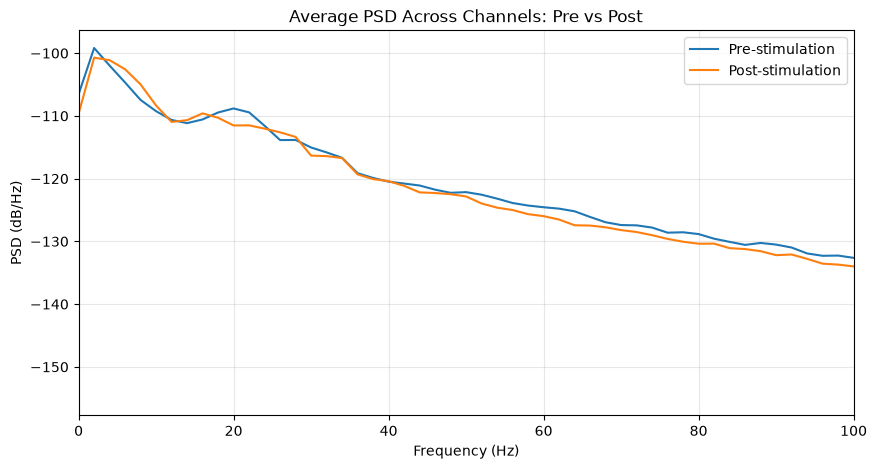

In [15]:
plt.figure(figsize=(10, 5))

plt.plot(
    frequencies,
    10 * np.log10(mean_pre_psd),
    label="Pre-stimulation"
)

plt.plot(
    frequencies,
    10 * np.log10(mean_post_psd),
    label="Post-stimulation"
)

plt.xlim(0, 100)
plt.xlabel("Frequency (Hz)")
plt.ylabel("PSD (dB/Hz)")
plt.title("Average PSD Across Channels: Pre vs Post")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

### Average PSD Across Channels: Pre- vs Post-Stimulation

**Method**

The PSD estimates from all 31 channels were averaged separately for the pre-stimulation and post-stimulation epochs. The resulting average spectra were converted to a decibel scale using \(10\log_{10}(\mathrm{PSD})\) and plotted over the 0–100 Hz frequency range.

**Observations**

- Both spectra show their highest PSD values at low frequencies, particularly around 2–4 Hz.
- PSD generally decreases as frequency increases.
- The two curves remain relatively close throughout the frequency range.
- Above approximately 40 Hz, the pre-stimulation average is generally slightly higher than the post-stimulation average.

**Limitations**

This plot represents an average across all 31 channels. It may conceal differences between individual channels, particularly because some channels have substantially higher PSD values than others.

These observations describe the estimated spectral distributions and do not establish the cause of the differences between epochs.

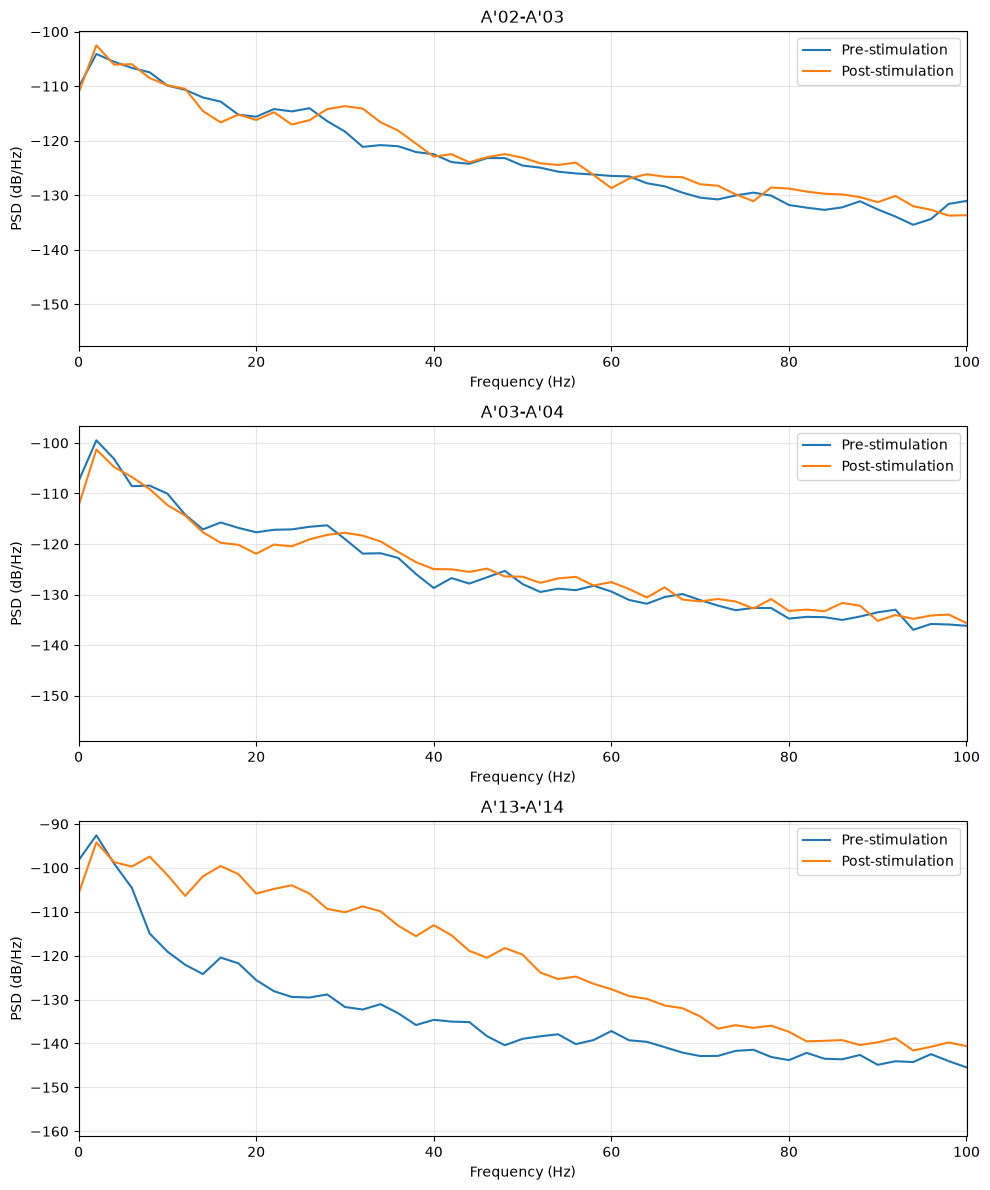

In [16]:
selected_channels = [
    "A'02-A'03",
    "A'03-A'04",
    "A'13-A'14"
]

fig, axes = plt.subplots(3, 1, figsize=(10, 12))

for ax, channel in zip(axes, selected_channels):

    channel_idx = raw.ch_names.index(channel)

    ax.plot(
        frequencies,
        10 * np.log10(pre_psd[channel_idx]),
        label="Pre-stimulation"
    )

    ax.plot(
        frequencies,
        10 * np.log10(post_psd[channel_idx]),
        label="Post-stimulation"
    )

    ax.set_xlim(0, 100)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("PSD (dB/Hz)")
    ax.set_title(channel)
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Individual Channel PSD Comparisons

**Observations**

- **A'02-A'03:** The pre- and post-stimulation spectra show broadly similar patterns to the channel-averaged spectrum.
- **A'03-A'04:** The two spectra approach one another around 100 Hz. Their trajectories suggest a possible crossing beyond the displayed frequency range, although this cannot be confirmed from the current plot.
- **A'13-A'14:** The spectra show a more pronounced separation. The pre-stimulation PSD is lower towards the upper end of the displayed frequency range.

**Limitations**

The plots show only frequencies between 0 and 100 Hz. Therefore, possible differences or intersections beyond this range cannot be established. These observations are descriptive and do not identify the causes of the spectral differences.